# Bitcoin Fraud Ring Detection with GraphSAGE

End-to-end Colab cells:

1. Upload Elliptic CSV zip files.
2. Preprocess features exactly once and save normalization artifacts.
3. Train GraphSAGE without changing the deployment architecture.
4. Test and tune threshold.
5. Detect fraud rings.
6. Save all outputs, including one draggable HTML for all rings and one draggable HTML per ring.



In [1]:
!pip -q install torch-geometric networkx scikit-learn pandas numpy matplotlib



     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 22.7 MB/s eta 0:00:00


In [2]:
import json
import os
import shutil
import warnings
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from google.colab import files
from networkx.algorithms.community import label_propagation_communities
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.utils.class_weight import compute_class_weight
from torch_geometric.data import Data
from torch_geometric.nn import SAGEConv

warnings.filterwarnings("ignore")
torch.manual_seed(42)
np.random.seed(42)

OUT_DIR = Path("outputs")
RING_DIR = OUT_DIR / "rings"
ARTIFACT_DIR = Path("artifacts")
OUT_DIR.mkdir(exist_ok=True)
RING_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(exist_ok=True)

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())



PyTorch: 2.11.0+cpu
CUDA: False


In [4]:
raw_features = pd.read_csv("elliptic_txs_features.csv",  header=None)
raw_edges    = pd.read_csv("elliptic_txs_edgelist.csv")
raw_labels  = pd.read_csv("elliptic_txs_classes.csv")

print(f'features: {raw_features.shape}  edges: {raw_edges.shape}  labels: {raw_labels.shape}')
assert raw_features.shape[0] > 200_000, 'WRONG FILE — need full Elliptic CSV (203769 rows)'
print(raw_labels.iloc[:,1].value_counts())
print('Files OK')



features: (203769, 167)  edges: (234355, 2)  labels: (203769, 2)
class
unknown    157205
2           42019
1            4545
Name: count, dtype: int64
Files OK


## Feature preprocessing

Important:

- `txId` is used only for mapping.
- Model input is exactly 166 columns: `time_step + 165 features`.
- We save `col_min.npy`, `col_rng.npy`, and `col_median.npy` for deployment.



In [5]:

tx_ids = raw_features.iloc[:, 0].astype(np.int64).values
id_map = {int(tx): idx for idx, tx in enumerate(tx_ids)}
time_steps = raw_features.iloc[:, 1].astype(np.int64).values

# Time-based split
train_period = time_steps <= 30
val_period = (time_steps >= 31) & (time_steps <= 35)
test_period = time_steps >= 36

assert train_period.any() and val_period.any() and test_period.any()
assert train_period.sum() + val_period.sum() + test_period.sum() == len(time_steps)

# Fit preprocessing ONLY on training-period features
feat_raw = raw_features.iloc[:, 1:].values.astype(np.float32)
train_features = feat_raw[train_period]

col_median = np.nanmedian(train_features, axis=0).astype(np.float32)
col_median = np.nan_to_num(col_median, nan=0.0)

missing_rows, missing_cols = np.where(~np.isfinite(feat_raw))
feat_raw[missing_rows, missing_cols] = col_median[missing_cols]

train_filled = feat_raw[train_period]
col_min = train_filled.min(axis=0).astype(np.float32)
col_rng = (train_filled.max(axis=0) - col_min).astype(np.float32)
col_rng[col_rng == 0] = 1.0

feat_norm = ((feat_raw - col_min) / col_rng).astype(np.float32)

# Separate experiment output: preserve existing artifacts
ARTIFACT_DIR = Path("artifacts_leakage_controlled")
ARTIFACT_DIR.mkdir(exist_ok=True)

np.save(ARTIFACT_DIR / "col_min.npy", col_min)
np.save(ARTIFACT_DIR / "col_rng.npy", col_rng)
np.save(ARTIFACT_DIR / "col_median.npy", col_median)

x = torch.tensor(feat_norm, dtype=torch.float32)

assert x.shape == (len(tx_ids), 166)
assert torch.isfinite(x).all()

print("Training-period nodes:", train_period.sum())
print("Validation-period nodes:", val_period.sum())
print("Testing-period nodes:", test_period.sum())
print("Features:", tuple(x.shape))
print("Normalizer fitted using training-period nodes only.")


Training-period nodes: 123287
Validation-period nodes: 18485
Testing-period nodes: 61997
Features: (203769, 166)
Normalizer fitted using training-period nodes only.


## Build original Elliptic graph



In [6]:
edge_df = raw_edges.copy()
edge_df.columns = ["txId1", "txId2"]
edge_df["src"] = edge_df["txId1"].astype(np.int64).map(id_map)
edge_df["dst"] = edge_df["txId2"].astype(np.int64).map(id_map)
edge_df = edge_df.dropna(subset=["src", "dst"])

src_idx = edge_df["src"].astype(np.int64).values
dst_idx = edge_df["dst"].astype(np.int64).values
edge_index = torch.tensor(np.stack([src_idx, dst_idx]), dtype=torch.long)

assert edge_index.shape[0] == 2
assert edge_index.max().item() < x.shape[0]

print("edge_index.shape:", tuple(edge_index.shape))



edge_index.shape: (2, 234355)


## Labels and train/test split

Elliptic labels:

- `1` means illicit.
- `2` means licit.
- `unknown` is ignored during supervised training/testing.



In [8]:

# Prepare transaction labels
labels_df = raw_labels.copy()
labels_df.columns = ["txId", "class"]

labels_df["node_idx"] = (
    labels_df["txId"].astype(np.int64).map(id_map)
)

labels_df = labels_df.dropna(subset=["node_idx"]).copy()
labels_df["node_idx"] = labels_df["node_idx"].astype(np.int64)

# Elliptic labels: 1 = illicit, 2 = licit, unknown = unlabeled
labels_df["y"] = (
    labels_df["class"]
    .astype(str)
    .map({"unknown": -1, "2": 0, "1": 1})
)

y_arr = np.full(len(tx_ids), -1, dtype=np.int64)
y_arr[labels_df["node_idx"].values] = labels_df["y"].values

y = torch.tensor(y_arr, dtype=torch.long)

# Chronological labeled-node masks
labeled = y_arr >= 0

train_mask = torch.tensor(
    labeled & train_period, dtype=torch.bool
)
val_mask = torch.tensor(
    labeled & val_period, dtype=torch.bool
)
test_mask = torch.tensor(
    labeled & test_period, dtype=torch.bool
)

# Build PyTorch Geometric data object
data = Data(x=x, edge_index=edge_index, y=y)

# Validate split
assert not (train_mask & val_mask).any()
assert not (train_mask & test_mask).any()
assert not (val_mask & test_mask).any()

for name, mask in [
    ("Train", train_mask),
    ("Validation", val_mask),
    ("Test", test_mask),
]:
    selected = y[mask]
    print(
        f"{name}: {len(selected):,} labeled nodes | "
        f"Illicit: {(selected == 1).sum().item():,} | "
        f"Licit: {(selected == 0).sum().item():,}"
    )

print("Unlabeled:", (y == -1).sum().item())
print("Data:", data)



Train: 26,905 labeled nodes | Illicit: 2,954 | Licit: 23,951
Validation: 4,330 labeled nodes | Illicit: 690 | Licit: 3,640
Test: 15,329 labeled nodes | Illicit: 901 | Licit: 14,428
Unlabeled: 157205
Data: Data(x=[203769, 166], edge_index=[2, 234355], y=[203769])


In [9]:

# Build chronological graph snapshots.
# These retain historical context without exposing future nodes.

def create_temporal_graph(max_step):
    allowed = time_steps <= max_step

    # Original node indices included in this snapshot
    node_ids = np.flatnonzero(allowed)

    # Map global node indices to snapshot-local indices
    mapping = np.full(len(time_steps), -1, dtype=np.int64)
    mapping[node_ids] = np.arange(len(node_ids))

    # Keep only edges whose endpoints are available
    src = edge_index[0].cpu().numpy()
    dst = edge_index[1].cpu().numpy()

    keep_edges = allowed[src] & allowed[dst]

    local_edges = np.stack([
        mapping[src[keep_edges]],
        mapping[dst[keep_edges]]
    ])

    snapshot = Data(
        x=x[node_ids],
        edge_index=torch.tensor(local_edges, dtype=torch.long),
        y=y[node_ids]
    )

    return snapshot, node_ids


train_data, train_ids = create_temporal_graph(30)
val_data, val_ids = create_temporal_graph(35)
test_data, test_ids = create_temporal_graph(49)

# Create labeled masks within each snapshot
train_local_mask = train_data.y >= 0

val_local_mask = (
    (val_data.y >= 0) &
    (torch.tensor(time_steps[val_ids]) >= 31)
)

test_local_mask = (
    (test_data.y >= 0) &
    (torch.tensor(time_steps[test_ids]) >= 36)
)

print("Training graph:", train_data)
print("Validation graph:", val_data)
print("Testing graph:", test_data)

print("Train labels:", int(train_local_mask.sum()))
print("Validation labels:", int(val_local_mask.sum()))
print("Test labels:", int(test_local_mask.sum()))

assert int(train_local_mask.sum()) == int(train_mask.sum())
assert int(val_local_mask.sum()) == int(val_mask.sum())
assert int(test_local_mask.sum()) == int(test_mask.sum())


Training graph: Data(x=[123287, 166], edge_index=[2, 142784], y=[123287])
Validation graph: Data(x=[141772, 166], edge_index=[2, 163194], y=[141772])
Testing graph: Data(x=[203769, 166], edge_index=[2, 234355], y=[203769])
Train labels: 26905
Validation labels: 4330
Test labels: 15329


## GraphSAGE model



In [10]:

class FocalLoss(torch.nn.Module):
    def __init__(self, gamma=2.0, alpha=None):
        super().__init__()
        self.gamma = gamma
        self.alpha = alpha

    def forward(self, logits, targets):
        ce = F.cross_entropy(
            logits, targets,
            weight=self.alpha,
            reduction="none"
        )
        return (((1 - torch.exp(-ce)) ** self.gamma) * ce).mean()


class GraphSAGE(torch.nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        self.c1 = SAGEConv(in_channels, 256)
        self.c2 = SAGEConv(256, 128)
        self.c3 = SAGEConv(128, 64)
        self.c4 = SAGEConv(64, 2)

        self.b1 = torch.nn.BatchNorm1d(256)
        self.b2 = torch.nn.BatchNorm1d(128)
        self.b3 = torch.nn.BatchNorm1d(64)
        self.drop = torch.nn.Dropout(0.4)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index
        x = F.relu(self.b1(self.c1(x, edge_index)))
        x = self.drop(x)
        x = F.relu(self.b2(self.c2(x, edge_index)))
        x = self.drop(x)
        x = F.relu(self.b3(self.c3(x, edge_index)))
        x = self.drop(x)
        return self.c4(x, edge_index)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

train_data = train_data.to(device)
val_data = val_data.to(device)

train_local_mask = train_local_mask.to(device)
val_local_mask = val_local_mask.to(device)

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=train_data.y[train_local_mask].cpu().numpy()
)

alpha = torch.tensor(
    weights, dtype=torch.float32, device=device
)

criterion = FocalLoss(gamma=2.0, alpha=alpha)

model = GraphSAGE(train_data.num_features).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.005,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=200,
    eta_min=1e-5
)

print("Device:", device)
print("Class weights:", weights)
print("Model parameters:",
      sum(p.numel() for p in model.parameters()))
print("Training nodes:", train_data.num_nodes)
print("Validation nodes:", val_data.num_nodes)


Device: cpu
Class weights: [0.56166757 4.55399458]
Model parameters: 168514
Training nodes: 123287
Validation nodes: 141772


## Train



In [11]:

from sklearn.metrics import average_precision_score, roc_auc_score

best_pr_auc = -1.0
best_epoch = 0
history = []

# Save the new experiment separately
checkpoint_path = ARTIFACT_DIR / "graphsage_model.pt"

for epoch in range(1, 201):
    # Training
    model.train()
    optimizer.zero_grad()

    logits = model(train_data)
    loss = criterion(
        logits[train_local_mask],
        train_data.y[train_local_mask]
    )

    loss.backward()
    optimizer.step()
    scheduler.step()

    # Validation only
    if epoch % 10 == 0:
        model.eval()

        with torch.no_grad():
            val_logits = model(val_data)

            val_probs = F.softmax(
                val_logits, dim=1
            )[:, 1][val_local_mask].cpu().numpy()

            val_y = (
                val_data.y[val_local_mask]
                .cpu().numpy()
            )

        pr_auc = average_precision_score(val_y, val_probs)
        roc_auc = roc_auc_score(val_y, val_probs)

        history.append({
            "epoch": epoch,
            "train_loss": float(loss.item()),
            "val_pr_auc": float(pr_auc),
            "val_roc_auc": float(roc_auc)
        })

        if pr_auc > best_pr_auc:
            best_pr_auc = pr_auc
            best_epoch = epoch

            torch.save(
                model.state_dict(),
                checkpoint_path
            )

        print(
            f"Epoch {epoch:03d} | "
            f"Loss {loss.item():.4f} | "
            f"Val PR-AUC {pr_auc:.4f} | "
            f"Val ROC-AUC {roc_auc:.4f}"
        )

# Restore the best validation checkpoint
model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
)

pd.DataFrame(history).to_csv(
    OUT_DIR / "training_history_leakage_controlled.csv",
    index=False
)

print("\nTraining complete.")
print("Best epoch:", best_epoch)
print("Best validation PR-AUC:", round(best_pr_auc, 4))
print("Checkpoint:", checkpoint_path)


Epoch 010 | Loss 0.1326 | Val PR-AUC 0.3948 | Val ROC-AUC 0.7663
Epoch 020 | Loss 0.0964 | Val PR-AUC 0.5936 | Val ROC-AUC 0.8900
Epoch 030 | Loss 0.0760 | Val PR-AUC 0.8254 | Val ROC-AUC 0.9487
Epoch 040 | Loss 0.0649 | Val PR-AUC 0.8578 | Val ROC-AUC 0.9587
Epoch 050 | Loss 0.0546 | Val PR-AUC 0.8526 | Val ROC-AUC 0.9599
Epoch 060 | Loss 0.0493 | Val PR-AUC 0.8741 | Val ROC-AUC 0.9634
Epoch 070 | Loss 0.0442 | Val PR-AUC 0.8424 | Val ROC-AUC 0.9592
Epoch 080 | Loss 0.0398 | Val PR-AUC 0.8702 | Val ROC-AUC 0.9665
Epoch 090 | Loss 0.0364 | Val PR-AUC 0.8667 | Val ROC-AUC 0.9679
Epoch 100 | Loss 0.0334 | Val PR-AUC 0.8840 | Val ROC-AUC 0.9709
Epoch 110 | Loss 0.0317 | Val PR-AUC 0.8865 | Val ROC-AUC 0.9718
Epoch 120 | Loss 0.0292 | Val PR-AUC 0.8921 | Val ROC-AUC 0.9734
Epoch 130 | Loss 0.0283 | Val PR-AUC 0.8918 | Val ROC-AUC 0.9738
Epoch 140 | Loss 0.0264 | Val PR-AUC 0.9009 | Val ROC-AUC 0.9758
Epoch 150 | Loss 0.0240 | Val PR-AUC 0.9153 | Val ROC-AUC 0.9785
Epoch 160 | Loss 0.0235 |

In [12]:

from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score
)

# Use the best checkpoint selected in Step 11
model.eval()

with torch.no_grad():
    val_logits = model(val_data)

    val_probs = F.softmax(
        val_logits, dim=1
    )[:, 1][val_local_mask].cpu().numpy()

    val_y = (
        val_data.y[val_local_mask]
        .cpu().numpy()
    )

# Find the threshold maximizing validation F1
precision, recall, thresholds = precision_recall_curve(
    val_y, val_probs
)

# Each threshold corresponds to precision/recall[:-1]
f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-8)
)

best_idx = int(np.argmax(f1_scores))
THRESHOLD = float(thresholds[best_idx])

val_pred = (val_probs >= THRESHOLD).astype(int)

print("Selected threshold:", round(THRESHOLD, 6))
print("Validation Precision:",
      round(precision_score(val_y, val_pred, zero_division=0), 4))
print("Validation Recall:",
      round(recall_score(val_y, val_pred, zero_division=0), 4))
print("Validation F1:",
      round(f1_score(val_y, val_pred, zero_division=0), 4))

np.save(
    ARTIFACT_DIR / "threshold.npy",
    np.array(THRESHOLD, dtype=np.float32)
)


Selected threshold: 0.802532
Validation Precision: 0.862
Validation Recall: 0.887
Validation F1: 0.8743


In [13]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)
import json

# Freeze the selected model and threshold
model.eval()

# Test graph has not been used for checkpoint selection
test_data = test_data.to(device)
test_local_mask = test_local_mask.to(device)

with torch.no_grad():
    test_logits = model(test_data)
    test_probs = F.softmax(
        test_logits, dim=1
    )[:, 1][test_local_mask].cpu().numpy()

test_y = test_data.y[test_local_mask].cpu().numpy()

# Threshold was selected on validation only
test_pred = (test_probs >= THRESHOLD).astype(int)

results = {
    "test_samples": int(len(test_y)),
    "selected_epoch": int(best_epoch),
    "validation_threshold": float(THRESHOLD),
    "test_roc_auc": float(roc_auc_score(test_y, test_probs)),
    "test_pr_auc": float(average_precision_score(test_y, test_probs)),
    "test_precision": float(precision_score(test_y, test_pred, zero_division=0)),
    "test_recall": float(recall_score(test_y, test_pred, zero_division=0)),
    "test_f1": float(f1_score(test_y, test_pred, zero_division=0))
}

print("FINAL HELD-OUT TEST RESULTS")
print("-" * 40)

for metric, value in results.items():
    print(f"{metric}: {value:.4f}" if isinstance(value, float)
          else f"{metric}: {value}")

print("\nClassification report:")
print(classification_report(
    test_y, test_pred,
    target_names=["Licit", "Illicit"],
    digits=4,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(test_y, test_pred))

# Save evaluation for GitHub/README
OUT_DIR.mkdir(exist_ok=True)

with open(
    OUT_DIR / "final_test_metrics.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(results, f, indent=2)

print("\nMetrics saved successfully.")


FINAL HELD-OUT TEST RESULTS
----------------------------------------
test_samples: 15329
selected_epoch: 150
validation_threshold: 0.8025
test_roc_auc: 0.9042
test_pr_auc: 0.6070
test_precision: 0.5740
test_recall: 0.6115
test_f1: 0.5922

Classification report:
              precision    recall  f1-score   support

       Licit     0.9756    0.9717    0.9736     14428
     Illicit     0.5740    0.6115    0.5922       901

    accuracy                         0.9505     15329
   macro avg     0.7748    0.7916    0.7829     15329
weighted avg     0.9520    0.9505    0.9512     15329

Confusion matrix:
[[14019   409]
 [  350   551]]

Metrics saved successfully.


In [14]:

from pathlib import Path
import shutil
from google.colab import files

export_dir = Path("validated_graphsage_export")

if export_dir.exists():
    shutil.rmtree(export_dir)

(export_dir / "artifacts").mkdir(parents=True)
(export_dir / "evaluation").mkdir(parents=True)

for name in [
    "graphsage_model.pt",
    "col_min.npy",
    "col_rng.npy",
    "col_median.npy",
    "threshold.npy"
]:
    shutil.copy2(
        ARTIFACT_DIR / name,
        export_dir / "artifacts" / name
    )

for name in [
    "final_test_metrics.json",
    "training_history_leakage_controlled.csv"
]:
    shutil.copy2(
        OUT_DIR / name,
        export_dir / "evaluation" / name
    )

zip_path = shutil.make_archive(
    "validated_graphsage_export",
    "zip",
    export_dir
)

print("Export created:", zip_path)
print("Artifacts:", sorted(p.name for p in
      (export_dir / "artifacts").iterdir()))

files.download(zip_path)


Export created: /content/validated_graphsage_export.zip
Artifacts: ['col_median.npy', 'col_min.npy', 'col_rng.npy', 'graphsage_model.pt', 'threshold.npy']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Evaluate and tune threshold



optimal threshold: 0.942
              precision    recall  f1-score   support

       licit     0.9752    0.9895    0.9823     15587
     illicit     0.8089    0.6371    0.7128      1083

    accuracy                         0.9666     16670
   macro avg     0.8920    0.8133    0.8476     16670
weighted avg     0.9644    0.9666    0.9648     16670

ROC-AUC: 0.907
PR-AUC: 0.6977


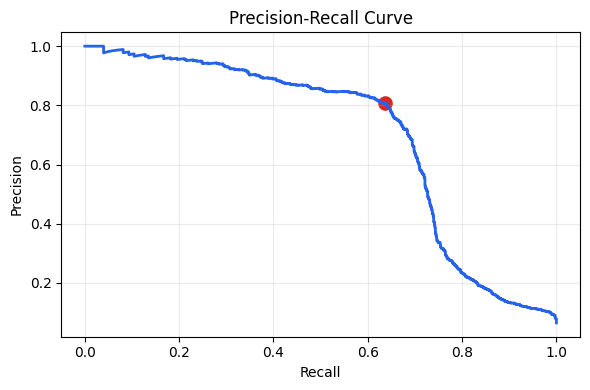

In [ ]:
model.eval()
with torch.no_grad():
    all_logits = model(data)
    all_probs = F.softmax(all_logits, dim=1)[:, 1].detach().cpu().numpy()

test_y = data.y[test_mask].detach().cpu().numpy()
test_probs = all_probs[test_mask.detach().cpu().numpy()]

precision, recall, thresholds = precision_recall_curve(test_y, test_probs)
f1 = 2 * precision * recall / (precision + recall + 1e-8)
best_idx = int(np.argmax(f1))
THRESHOLD = float(thresholds[min(best_idx, len(thresholds) - 1)])
test_pred = (test_probs >= THRESHOLD).astype(int)

print("optimal threshold:", round(THRESHOLD, 4))
print(classification_report(test_y, test_pred, target_names=["licit", "illicit"], digits=4))
print("ROC-AUC:", round(roc_auc_score(test_y, test_probs), 4))
print("PR-AUC:", round(average_precision_score(test_y, test_probs), 4))

plt.figure(figsize=(6, 4))
plt.plot(recall, precision, color="#2563eb", linewidth=2)
plt.scatter([recall[best_idx]], [precision[best_idx]], color="#dc2626", s=90)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUT_DIR / "precision_recall_curve.png", dpi=160)
plt.show()



## Save node predictions



In [ ]:
preds = (all_probs >= THRESHOLD).astype(np.int64)
node_predictions = pd.DataFrame({
    "node_index": np.arange(len(tx_ids)),
    "txId": tx_ids,
    "time_step": time_steps,
    "true_label": y_arr,
    "fraud_probability": all_probs,
    "prediction": preds,
})
node_predictions.to_csv(OUT_DIR / "node_predictions.csv", index=False)
display(node_predictions.sort_values("fraud_probability", ascending=False).head(10))



,node_index,txId,time_step,true_label,fraud_probability,prediction
155770,155770,162454779,39,-1,0.999906,1
156235,156235,149599377,39,-1,0.999893,1
155849,155849,162474618,39,-1,0.999866,1
160387,160387,97087192,40,-1,0.999837,1
154824,154824,148792582,39,-1,0.999832,1
152924,152924,12830021,38,1,0.999730,1
84958,84958,362950094,19,-1,0.999679,1
84957,84957,356195196,19,-1,0.999666,1
156410,156410,151212632,39,-1,0.999646,1
83192,83192,363768605,19,-1,0.999623,1


## Detect fraud rings

Ring logic:

- First create a graph from the original transaction edges.
- Keep predicted-illicit nodes.
- Connected components of those nodes are direct fraud rings.
- Also run label propagation communities and keep suspicious communities.



In [ ]:
G = nx.Graph()
G.add_nodes_from(range(len(tx_ids)))
G.add_edges_from(zip(src_idx.tolist(), dst_idx.tolist()))

flagged_nodes = np.where(preds == 1)[0].tolist()
flagged_graph = G.subgraph(flagged_nodes).copy()

fraud_rings = []
for comp in nx.connected_components(flagged_graph):
    if len(comp) < 3:
        continue
    nodes = sorted(int(n) for n in comp)
    sub = G.subgraph(nodes)
    fraud_rings.append({
        "ring_id": len(fraud_rings),
        "method": "predicted_illicit_connected_component",
        "size": len(nodes),
        "edge_count": int(sub.number_of_edges()),
        "avg_fraud_probability": float(np.mean(all_probs[nodes])),
        "max_fraud_probability": float(np.max(all_probs[nodes])),
        "node_indices": nodes,
        "txIds": [int(tx_ids[n]) for n in nodes],
    })
fraud_rings = sorted(fraud_rings, key=lambda r: (r["avg_fraud_probability"], r["size"]), reverse=True)
for i, ring in enumerate(fraud_rings):
    ring["ring_id"] = i

community_rings = []
for comm in label_propagation_communities(G):
    nodes = sorted(int(n) for n in comm)
    if len(nodes) < 3:
        continue
    pred_ratio = float(np.mean(preds[nodes]))
    avg_prob = float(np.mean(all_probs[nodes]))
    if pred_ratio >= 0.4 and avg_prob >= THRESHOLD * 0.6:
        sub = G.subgraph(nodes)
        community_rings.append({
            "ring_id": len(community_rings),
            "method": "label_propagation_community",
            "size": len(nodes),
            "edge_count": int(sub.number_of_edges()),
            "pred_illicit_ratio": pred_ratio,
            "avg_fraud_probability": avg_prob,
            "max_fraud_probability": float(np.max(all_probs[nodes])),
            "node_indices": nodes,
            "txIds": [int(tx_ids[n]) for n in nodes],
        })
community_rings = sorted(community_rings, key=lambda r: (r["pred_illicit_ratio"], r["avg_fraud_probability"]), reverse=True)
for i, ring in enumerate(community_rings):
    ring["ring_id"] = i

print("fraud rings:", len(fraud_rings))
print("suspicious communities:", len(community_rings))



fraud rings: 432
suspicious communities: 1429


In [ ]:
summary_rows = []
for ring in fraud_rings:
    summary_rows.append({
        "ring_id": ring["ring_id"],
        "method": ring["method"],
        "size": ring["size"],
        "edge_count": ring["edge_count"],
        "avg_fraud_probability": ring["avg_fraud_probability"],
        "max_fraud_probability": ring["max_fraud_probability"],
    })

pd.DataFrame(summary_rows).to_csv(OUT_DIR / "rings_summary.csv", index=False)
with open(OUT_DIR / "fraud_rings.json", "w", encoding="utf-8") as f:
    json.dump(fraud_rings, f, indent=2)
with open(OUT_DIR / "community_rings.json", "w", encoding="utf-8") as f:
    json.dump(community_rings, f, indent=2)

display(pd.DataFrame(summary_rows).head(20))



,ring_id,method,size,edge_count,avg_fraud_probability,max_fraud_probability
0,0,predicted_illicit_connected_component,3,2,0.996831,0.998047
1,1,predicted_illicit_connected_component,3,2,0.995542,0.997046
2,2,predicted_illicit_connected_component,6,5,0.995381,0.999230
3,3,predicted_illicit_connected_component,3,2,0.994705,0.996873
4,4,predicted_illicit_connected_component,3,2,0.994583,0.995996
5,5,predicted_illicit_connected_component,5,4,0.994438,0.997583
6,6,predicted_illicit_connected_component,9,8,0.993437,0.996538
7,7,predicted_illicit_connected_component,31,30,0.993290,0.999438
8,8,predicted_illicit_connected_component,52,51,0.992046,0.999476
9,9,predicted_illicit_connected_component,3,2,0.991412,0.998283


## Draggable HTML visualizations

These files work as standalone browser files. You can drag any node; connected nodes move through the force layout.



In [ ]:
def make_visual_payload(rings, focus_ring_id=None, max_nodes=900, max_edges=2500):
    ring_by_node = {}
    for ring in rings:
        for node in ring["node_indices"]:
            ring_by_node[int(node)] = int(ring["ring_id"])

    if focus_ring_id is None:
        selected = set(ring_by_node.keys())
    else:
        ring = rings[int(focus_ring_id)]
        selected = set(map(int, ring["node_indices"]))
        for node in list(selected):
            selected.update(G.neighbors(node))

    if len(selected) > max_nodes:
        ranked = sorted(selected, key=lambda n: all_probs[n], reverse=True)
        selected = set(ranked[:max_nodes])

    vis_edges = []
    for s, d in zip(src_idx.tolist(), dst_idx.tolist()):
        if s in selected and d in selected:
            vis_edges.append({"source": int(s), "target": int(d)})
            if len(vis_edges) >= max_edges:
                break

    vis_nodes = []
    for node in sorted(selected):
        vis_nodes.append({
            "id": int(node),
            "txId": int(tx_ids[node]),
            "probability": float(all_probs[node]),
            "ring_id": ring_by_node.get(int(node)),
            "is_illicit": bool(preds[node] == 1),
            "time_step": int(time_steps[node]),
        })

    return {
        "nodes": vis_nodes,
        "edges": vis_edges,
        "rings": rings,
        "focus_ring_id": focus_ring_id,
    }


def write_force_graph_html(path, payload, title):
    html = f"""
<!doctype html>
<html>
<head>
<meta charset="utf-8">
<title>{title}</title>
<style>
html, body {{ margin: 0; height: 100%; background: #0b1017; color: #e8edf5; font-family: Inter, Segoe UI, Arial, sans-serif; }}
#top {{ height: 54px; display: flex; align-items: center; gap: 12px; padding: 0 16px; background: #111821; border-bottom: 1px solid #253142; }}
#badge {{ background: #dc2626; color: white; border-radius: 999px; padding: 4px 12px; font-weight: 800; font-size: 12px; }}
#title {{ font-weight: 800; font-size: 16px; }}
#meta {{ color: #9fb0c7; font-size: 13px; }}
#main {{ display: grid; grid-template-columns: 1fr 300px; height: calc(100% - 54px); }}
#graph {{ width: 100%; height: 100%; cursor: grab; }}
#graph.dragging {{ cursor: grabbing; }}
#side {{ border-left: 1px solid #253142; background: #111821; padding: 14px; overflow: auto; }}
.ring {{ padding: 9px 0; border-bottom: 1px solid #1f2a38; font-size: 12px; cursor: pointer; }}
.name {{ font-weight: 800; color: #f8fafc; }}
.dot {{ display: inline-block; width: 10px; height: 10px; border-radius: 99px; margin-right: 8px; }}
#hover {{ margin-top: 16px; color: #d7e3f5; font-size: 12px; line-height: 1.45; }}
button {{ background: #172234; border: 1px solid #34445c; color: #dce8fa; border-radius: 6px; height: 30px; padding: 0 12px; cursor: pointer; }}
</style>
</head>
<body>
<div id="top">
  <span id="badge">FRAUD RINGS</span>
  <span id="title">{title}</span>
  <span id="meta"></span>
  <button id="all">All Rings</button>
  <button id="fit">Fit</button>
  <button id="pause">Pause</button>
</div>
<div id="main">
  <canvas id="graph"></canvas>
  <aside id="side"><div id="rings"></div><div id="hover"></div></aside>
</div>
<script>
const graph = {json.dumps(payload)};
const canvas = document.getElementById("graph"), ctx = canvas.getContext("2d");
const colors = ["#ef4444","#f97316","#eab308","#84cc16","#22c55e","#14b8a6","#06b6d4","#3b82f6","#8b5cf6","#d946ef","#ec4899","#f43f5e"];
const nodes = graph.nodes || [], edges = graph.edges || [], rings = graph.rings || [];
const byId = new Map(nodes.map(n => [n.id, n]));
const ringMap = new Map();
rings.forEach(r => (r.node_indices || []).forEach(n => ringMap.set(Number(n), r.ring_id)));
nodes.forEach(n => {{ if (ringMap.has(n.id)) n.ring_id = ringMap.get(n.id); n.vx = 0; n.vy = 0; }});
let focusRing = graph.focus_ring_id, scale = 1, ox = 0, oy = 0, paused = false, drag = null, pan = null, hover = null;
function resize() {{ const r = canvas.getBoundingClientRect(); canvas.width = r.width; canvas.height = r.height; }}
function sx(x) {{ return x * scale + ox; }} function sy(y) {{ return y * scale + oy; }}
function wx(x) {{ return (x - ox) / scale; }} function wy(y) {{ return (y - oy) / scale; }}
function keepSet() {{ if (focusRing === null || focusRing === undefined || focusRing === "all") return new Set(nodes.map(n => n.id));
  const ring = rings.find(r => r.ring_id === Number(focusRing)); return new Set((ring ? ring.node_indices : []).map(Number)); }}
function ns() {{ const k = keepSet(); return nodes.filter(n => k.has(n.id)); }}
function es() {{ const k = keepSet(); return edges.filter(e => k.has(e.source) && k.has(e.target)); }}
function layout() {{ resize(); const show = ns(); const cols = Math.ceil(Math.sqrt(show.length || 1));
  show.forEach((n, i) => {{ const a = Math.PI * 2 * i / Math.max(1, show.length); const r = 80 + 5 * Math.sqrt(show.length);
    n.x = canvas.width / 2 + r * Math.cos(a) + (i % cols) * 4; n.y = canvas.height / 2 + r * Math.sin(a) + Math.floor(i / cols) * 4; }});
  fit(); }}
function fit() {{ const show = ns(); if (!show.length) return; const minX = Math.min(...show.map(n => n.x)), maxX = Math.max(...show.map(n => n.x));
  const minY = Math.min(...show.map(n => n.y)), maxY = Math.max(...show.map(n => n.y)); const pad = 80;
  scale = Math.min(canvas.width / Math.max(1, maxX - minX + pad * 2), canvas.height / Math.max(1, maxY - minY + pad * 2), 2);
  ox = canvas.width / 2 - scale * ((minX + maxX) / 2); oy = canvas.height / 2 - scale * ((minY + maxY) / 2); }}
function tick() {{ if (paused || drag) return; const show = ns(), links = es(); const cx = wx(canvas.width * .47), cy = wy(canvas.height * .52);
  show.forEach(n => {{ n.vx += (cx - n.x) * .001; n.vy += (cy - n.y) * .001; }});
  for (let i=0;i<show.length;i++) for (let j=i+1;j<show.length;j++) {{ const a=show[i], b=show[j], dx=a.x-b.x, dy=a.y-b.y, d2=Math.max(80, dx*dx+dy*dy), f=140/d2; a.vx+=dx*f; a.vy+=dy*f; b.vx-=dx*f; b.vy-=dy*f; }}
  links.forEach(e => {{ const s=byId.get(e.source), d=byId.get(e.target); if(!s||!d) return; const dx=d.x-s.x, dy=d.y-s.y, dist=Math.max(1, Math.hypot(dx,dy)), f=(dist-45)*.015; s.vx+=dx/dist*f; s.vy+=dy/dist*f; d.vx-=dx/dist*f; d.vy-=dy/dist*f; }});
  show.forEach(n => {{ n.vx*=.86; n.vy*=.86; n.x+=n.vx; n.y+=n.vy; }}); }}
function draw() {{ ctx.fillStyle="#0b1017"; ctx.fillRect(0,0,canvas.width,canvas.height); es().forEach(e => {{ const s=byId.get(e.source), d=byId.get(e.target); if(!s||!d) return; ctx.strokeStyle=s.ring_id===d.ring_id?"rgba(250,204,21,.30)":"rgba(148,163,184,.16)"; ctx.beginPath(); ctx.moveTo(sx(s.x),sy(s.y)); ctx.lineTo(sx(d.x),sy(d.y)); ctx.stroke(); }});
  ns().forEach(n => {{ const c=n.ring_id!==null&&n.ring_id!==undefined?colors[n.ring_id%colors.length]:null; ctx.fillStyle=c||(n.is_illicit?"#facc15":"#38bdf8"); ctx.strokeStyle=hover&&hover.id===n.id?"#fff":(n.is_illicit?"#fde047":"#0b1017"); ctx.lineWidth=hover&&hover.id===n.id?3:1.5; ctx.beginPath(); ctx.arc(sx(n.x),sy(n.y),n.is_illicit?6:4,0,Math.PI*2); ctx.fill(); ctx.stroke(); }}); }}
function hit(mx,my) {{ let best=null, bd=999; ns().forEach(n => {{ const d=Math.hypot(sx(n.x)-mx, sy(n.y)-my); if(d<bd) {{ best=n; bd=d; }} }}); return bd<=16?best:null; }}
function renderRings() {{ document.getElementById("meta").textContent = `${{nodes.length}} nodes | ${{edges.length}} edges | ${{rings.length}} rings`; const box=document.getElementById("rings"); box.innerHTML=""; rings.slice(0,80).forEach(r => {{ const div=document.createElement("div"); div.className="ring"; div.innerHTML=`<span class="dot" style="background:${{colors[r.ring_id%colors.length]}}"></span><span class="name">Ring ${{r.ring_id}}</span><br>${{r.size}} nodes | avg p=${{Number(r.avg_fraud_probability).toFixed(3)}}`; div.onclick=()=>{{focusRing=r.ring_id; layout(); renderRings();}}; box.appendChild(div); }}); }}
canvas.onmousemove = ev => {{ const r=canvas.getBoundingClientRect(), mx=ev.clientX-r.left, my=ev.clientY-r.top; if(drag) {{ drag.x=wx(mx); drag.y=wy(my); drag.vx=0; drag.vy=0; return; }} if(pan) {{ ox=pan.ox+ev.clientX-pan.x; oy=pan.oy+ev.clientY-pan.y; return; }} hover=hit(mx,my); document.getElementById("hover").innerHTML=hover?`<b>txId ${{hover.txId}}</b><br>node ${{hover.id}}<br>p=${{Number(hover.probability).toFixed(4)}}`:""; }};
canvas.onmousedown = ev => {{ const r=canvas.getBoundingClientRect(); drag=hit(ev.clientX-r.left, ev.clientY-r.top); canvas.classList.add("dragging"); if(!drag) pan={{x:ev.clientX,y:ev.clientY,ox:ox,oy:oy}}; }};
window.onmouseup = () => {{ drag=null; pan=null; canvas.classList.remove("dragging"); }};
canvas.onwheel = ev => {{ ev.preventDefault(); const r=canvas.getBoundingClientRect(), mx=ev.clientX-r.left, my=ev.clientY-r.top, bx=wx(mx), by=wy(my); scale*=ev.deltaY<0?1.1:.9; scale=Math.max(.2,Math.min(5,scale)); ox=mx-bx*scale; oy=my-by*scale; }};
document.getElementById("all").onclick=()=>{{focusRing="all"; layout(); renderRings();}};
document.getElementById("fit").onclick=()=>{{fit();}};
document.getElementById("pause").onclick=ev=>{{paused=!paused; ev.target.textContent=paused?"Play":"Pause";}};
function frame() {{ tick(); draw(); requestAnimationFrame(frame); }}
layout(); renderRings(); frame();
</script>
</body>
</html>
"""
    Path(path).write_text(html, encoding="utf-8")


all_payload = make_visual_payload(fraud_rings, focus_ring_id=None)
write_force_graph_html(OUT_DIR / "fraud_rings_all_interactive.html", all_payload, f"All Fraud Rings - {len(fraud_rings)} rings")

for ring in fraud_rings:
    payload = make_visual_payload(fraud_rings, focus_ring_id=ring["ring_id"], max_nodes=500, max_edges=1200)
    write_force_graph_html(RING_DIR / f"ring_{ring['ring_id']:03d}.html", payload, f"Fraud Ring {ring['ring_id']}")

print("saved:", OUT_DIR / "fraud_rings_all_interactive.html")
print("saved per-ring HTML files:", len(list(RING_DIR.glob("ring_*.html"))))



saved: outputs/fraud_rings_all_interactive.html
saved per-ring HTML files: 432


## Package and download outputs



In [ ]:
shutil.make_archive("fraud_detection_outputs", "zip", OUT_DIR)
shutil.make_archive("graphsage_artifacts", "zip", ARTIFACT_DIR)

files.download("fraud_detection_outputs.zip")
files.download("graphsage_artifacts.zip")

print("Done.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Done.
